# Assignment 12: A Reusable ML Pipeline for Customer Churn

Build one pipeline that automatically:

1. handles missing numerical values
2. scales numerical features
3. encodes categorical features
4. trains a model
5. generates predictions

The pipeline has to work on **raw** test data, with no manual preprocessing.

The classwork built this on the Airlines Delay dataset. Here I use the **Telco Customer Churn** dataset (7,043 customers, predict whether a customer leaves), the same dataset from the Logistic Regression project earlier in the course. It's a good fit because it mixes 3 numerical columns with 16 categorical ones, and it has a real data-quality problem: `TotalCharges` is stored as text and is blank for some customers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, roc_auc_score

## Load the Raw Data

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

`TotalCharges` should be a number but pandas read it as text. The reason: some customers have a blank space `" "` instead of a value.

In [4]:
blank = df["TotalCharges"].str.strip() == ""
print("Customers with blank TotalCharges:", blank.sum())
df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Customers with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


These are all brand-new customers (`tenure` = 0) who haven't been billed yet. In real use, new raw data will contain these blanks too, so **fixing them is the pipeline's job**, not something I do by hand to the dataset. That's why I leave the raw data exactly as it is and only separate the features from the target.

## Split the Raw Data

The target `Churn` is "Yes"/"No", so I turn it into 1/0. This is the *label*, not a feature, so it isn't part of the preprocessing. The features `X` are left completely raw: text columns, blank strings, `customerID` and all.

In [5]:
X = df.drop(columns=["Churn"])
y = (df["Churn"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate (train): {:.1%}".format(y_train.mean()))
print("Blank TotalCharges in the raw test set:", (X_test["TotalCharges"].str.strip() == "").sum())

Train: (5634, 20)  Test: (1409, 20)
Churn rate (train): 26.5%
Blank TotalCharges in the raw test set: 3


## Define the Feature Groups

- **Numerical:** `tenure`, `MonthlyCharges`, `TotalCharges`
- **Categorical:** everything else that describes the customer. `SeniorCitizen` is stored as 0/1 but it is really a yes/no category, so it goes with the categoricals.
- **Not used:** `customerID` is a unique ID with no predictive meaning. Because it isn't listed in either group, the `ColumnTransformer` drops it automatically (`remainder="drop"`).

In [6]:
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
]

## Build the Pipeline

The pipeline has four stages. Each one is *fit* on the training data only and then simply *applied* to anything passed to `predict()`.

**Stage 0: Fix data types (`FunctionTransformer`)**
Converts `TotalCharges` from text to a number. Blank strings become `NaN`, a proper missing value that the imputer can recognise. Putting this inside the pipeline means raw data straight from the CSV can be passed in.

**Stage 1: Numerical branch**
- `SimpleImputer(strategy="median")` handles the missing numerical values. It learns the median of each numerical column from the training set and uses that to fill gaps in any future data. The median is used instead of the mean because `TotalCharges` is heavily skewed.
- `StandardScaler()` scales the features. `TotalCharges` runs into the thousands while `tenure` is at most 72, so without scaling the model would let the largest-unit column dominate.

**Stage 2: Categorical branch**
- `SimpleImputer(strategy="most_frequent")` is a safety net in case a future record arrives with a missing category.
- `OneHotEncoder(handle_unknown="ignore")` encodes the categories as 0/1 columns, the same as the classwork. `handle_unknown="ignore"` means a category never seen in training (e.g. a new payment method) becomes all zeros instead of crashing the pipeline.

**Stage 3: Model**
- `LogisticRegression` trains the classifier and generates predictions. The final `predict()` call runs every stage above automatically.

In [7]:
def fix_total_charges(data):
    data = data.copy()
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
    return data

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

def build_pipeline(model):
    """Same preprocessing every time; only the model at the end changes."""
    return Pipeline([
        ("fix_types", FunctionTransformer(fix_total_charges)),
        ("preprocessor", clone(preprocessor)),  # fresh copy so pipelines never share fitted state
        ("model", model),
    ])

churn_pipeline = build_pipeline(LogisticRegression(max_iter=1000))
churn_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fix_types', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function fix...t 0x116b3fd80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDi

## Train the Pipeline on Raw Training Data

One `fit` call. Internally this fixes the types, learns the medians, learns the scaling, learns the categories, transforms the data, and trains the model.

In [8]:
churn_pipeline.fit(X_train, y_train)

print("Values learned from the TRAINING set only:")
num_steps = churn_pipeline.named_steps["preprocessor"].named_transformers_["num"]
print("  Medians used for imputation:", dict(zip(numerical_features, num_steps.named_steps["imputer"].statistics_.round(2))))
print("  Means used for scaling:     ", dict(zip(numerical_features, num_steps.named_steps["scaler"].mean_.round(2))))

feature_names = churn_pipeline.named_steps["preprocessor"].get_feature_names_out()
print(f"\n{X_train.shape[1]} raw columns -> {len(feature_names)} model features after encoding")

Values learned from the TRAINING set only:
  Medians used for imputation: {'tenure': np.float64(29.0), 'MonthlyCharges': np.float64(70.5), 'TotalCharges': np.float64(1398.12)}
  Means used for scaling:      {'tenure': np.float64(32.49), 'MonthlyCharges': np.float64(64.93), 'TotalCharges': np.float64(2301.32)}

20 raw columns -> 46 model features after encoding


## Generate Predictions on the Raw Test Set

The test set is passed in exactly as it came out of the CSV: text `TotalCharges`, blank strings, `customerID`. No manual cleaning.

In [9]:
X_test.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,4376-KFVRS,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2
2280,2754-SDJRD,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55
2235,9917-KWRBE,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.2


In [10]:
y_pred = churn_pipeline.predict(X_test)
y_proba = churn_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_pred)))
print("ROC-AUC:  {:.4f}\n".format(roc_auc_score(y_test, y_proba)))
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

Accuracy: 0.8055
ROC-AUC:  0.8419

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



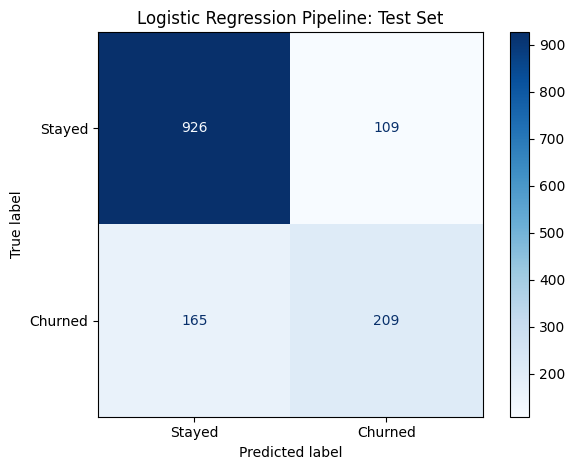

In [11]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Logistic Regression Pipeline: Test Set")
plt.tight_layout()
plt.show()

The test customers with blank `TotalCharges` were imputed and predicted like everyone else:

In [12]:
blank_test = X_test["TotalCharges"].str.strip() == ""
pd.DataFrame({
    "tenure": X_test.loc[blank_test, "tenure"],
    "raw TotalCharges": X_test.loc[blank_test, "TotalCharges"].map(repr),
    "churn probability": y_proba[blank_test.values].round(3),
    "prediction": np.where(y_pred[blank_test.values] == 1, "Churn", "Stay"),
})

,tenure,raw TotalCharges,churn probability,prediction
753,0,' ',0.066,Stay
5218,0,' ',0.169,Stay
936,0,' ',0.115,Stay


## Reusability 1: Swap the Model, Keep the Preprocessing

Because preprocessing lives inside the pipeline, trying a different model is a one-line change. Nothing about the data handling has to be rewritten.

In [13]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42),
}

rows = []
for name, model in candidates.items():
    pipe = build_pipeline(model).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    report = classification_report(y_test, pred, output_dict=True)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]), 4),
        "Churn Recall": round(report["1"]["recall"], 4),
        "Churn Precision": round(report["1"]["precision"], 4),
    })

pd.DataFrame(rows).set_index("Model")

,Accuracy,ROC-AUC,Churn Recall,Churn Precision
Model,,,,
Logistic Regression,0.8055,0.8419,0.5588,0.6572
Logistic Regression (balanced),0.7374,0.8414,0.7834,0.5034
Random Forest,0.7999,0.8410,0.5107,0.6586


All three reach almost the same ROC-AUC (~0.84), so with this preprocessing the data supports about the same level of separation regardless of model. The interesting difference is the trade-off: plain Logistic Regression has the best accuracy (80.6%) but catches only 56% of the customers who actually leave. Adding `class_weight="balanced"` raises churn recall to 78% at the cost of more false alarms. For a churn-prevention campaign, where missing a leaving customer costs more than sending an unnecessary retention offer, the balanced version could be the better business choice. Comparing these took three lines, which is the point of a reusable pipeline.

## Reusability 2: Predict for Brand-New Customers

The real test of a reusable pipeline: hand it new raw records, including the problems it might meet in production:

- Customer A: a new customer whose `TotalCharges` is blank `" "` (like the dataset's own new customers).
- Customer B: a long-term customer whose `MonthlyCharges` is completely missing (`None`).
- Customer C: a payment method, `"Crypto wallet"`, that never appeared in the training data.

In [14]:
new_customers = pd.DataFrame([
    {"customerID": "NEW-A", "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
     "tenure": 0, "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
     "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
     "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
     "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check", "MonthlyCharges": 95.5, "TotalCharges": " "},
    {"customerID": "NEW-B", "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes",
     "tenure": 65, "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "DSL",
     "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes",
     "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Two year",
     "PaperlessBilling": "No", "PaymentMethod": "Bank transfer (automatic)", "MonthlyCharges": None, "TotalCharges": "4500.25"},
    {"customerID": "NEW-C", "gender": "Male", "SeniorCitizen": 1, "Partner": "No", "Dependents": "No",
     "tenure": 12, "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
     "OnlineSecurity": "No", "OnlineBackup": "Yes", "DeviceProtection": "No", "TechSupport": "No",
     "StreamingTV": "No", "StreamingMovies": "No", "Contract": "One year",
     "PaperlessBilling": "Yes", "PaymentMethod": "Crypto wallet", "MonthlyCharges": 80.0, "TotalCharges": "960.0"},
])

new_customers[["customerID", "tenure", "Contract", "PaymentMethod", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,Contract,PaymentMethod,MonthlyCharges,TotalCharges
0,NEW-A,0,Month-to-month,Electronic check,95.5,
1,NEW-B,65,Two year,Bank transfer (automatic),NaN,4500.25
2,NEW-C,12,One year,Crypto wallet,80.0,960.0


In [15]:
results = new_customers[["customerID"]].copy()
results["churn probability"] = churn_pipeline.predict_proba(new_customers)[:, 1].round(3)
results["prediction"] = np.where(churn_pipeline.predict(new_customers) == 1, "Churn", "Stay")
results

,customerID,churn probability,prediction
0,NEW-A,0.823,Churn
1,NEW-B,0.006,Stay
2,NEW-C,0.375,Stay


All three predict without errors and with no manual cleaning. The predictions also make sense: the new month-to-month fiber customer paying by electronic check (A) is high risk, while the loyal two-year-contract customer (B) is very low risk.

## Reusability 3: Save and Reload the Pipeline

The whole fitted pipeline (data-type fix, medians, scaling, categories, and model) saves as one file. Anyone who loads it can predict on raw data straight away.

In [16]:
joblib.dump(churn_pipeline, "churn_pipeline.joblib")
loaded_pipeline = joblib.load("churn_pipeline.joblib")

same = (loaded_pipeline.predict(X_test) == y_pred).all()
print("Reloaded pipeline gives identical test predictions:", same)

Reloaded pipeline gives identical test predictions: True


## Summary

The final pipeline takes the raw CSV columns in and produces churn predictions out, with **80.6% accuracy and 0.842 ROC-AUC** on the untouched test set.

| Requirement | Where it happens in the pipeline |
|---|---|
| Handles missing numerical values | `FunctionTransformer` turns blank `TotalCharges` into `NaN`, then `SimpleImputer(strategy="median")` fills it (and any other missing number, like customer B's `MonthlyCharges`) with the training median. |
| Scales numerical features | `StandardScaler` in the numerical branch, fitted on training data only. |
| Encodes categorical features | `OneHotEncoder(handle_unknown="ignore")` in the categorical branch, with a most-frequent imputer in front as a safety net. |
| Trains a model | `LogisticRegression` as the final step; `fit(X_train, y_train)` trains everything in one call. |
| Generates predictions | `predict()` / `predict_proba()` on raw data. |
| Works without manually preprocessing the test data | The raw test set, three messy new customers and a reloaded copy of the pipeline were all predicted with zero manual cleaning. |

**Why a pipeline matters:** every value the preprocessing learns (medians, means, standard deviations, category lists) comes from the training set and is reused unchanged on new data. That prevents **data leakage** and **train/test mismatch** (e.g. a test set with a different set of categories producing a different number of columns). It also makes the whole workflow a single object you can retrain, swap models in, save, and deploy.